In [1]:
import mdtraj as md
import numpy as np
import networkx as nx
import os
import math
import pickle
import random
import numpy as np
from typing import List, Tuple, Dict

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GATv2Conv, global_mean_pool

from tqdm import tqdm
from scipy.stats import spearmanr



In [2]:
# ===================== PARAMETERS =====================
res_lig_cutoff = 0.8   # nm cutoff for ligand–residue edges
res_res_cutoff = 0.8   # nm cutoff for residue–residue edges
lambda_val = 5         # Å decay parameter
epsilon = 1e-8
graphs = []

# ===================== LOAD TRAJECTORY =====================
traj = md.load(
    "/media/arnav_ds04/PfHT1/holo_pfht1/extract_states/filtered_trajectory.xtc",
    top="/media/arnav_ds04/PfHT1/holo_pfht1/PfHT1_OF_with_glc_mix_memb-strip.prmtop"
)

protein_atoms = traj.top.select("protein and not element H")
ligand_atoms = traj.top.select("resname GLC and not element H")
ca_atoms = traj.top.select("protein and name CA")

protein_residues = [
    res for res in traj.top.residues if any(a.index in protein_atoms for a in res.atoms)
]



In [ ]:
# ===================== GRAPH GENERATION =====================
for frame_idx, frame in enumerate(tqdm(traj, desc="Building graphs")):
    residue_positions = {}

    # 1. Compute residue COM positions
    for res in protein_residues:
        res_atoms = [a.index for a in res.atoms if a.index in protein_atoms]
        if res_atoms:
            residue_positions[res.index] = frame.xyz[0, res_atoms, :].mean(axis=0)

    # 2. Protein COM (for centering)
    protein_com = np.mean(frame.xyz[0, protein_atoms, :], axis=0)

    # 3. Ligand COM (only for edge building, NOT features)
    ligand_pos = np.mean(frame.xyz[0, ligand_atoms, :], axis=0)

    # 4. z-coordinate target
    ligand_z = ligand_pos[2]

    # 5. Build node mapping: residues + ligand
    node_mapping = {res.index: idx for idx, res in enumerate(protein_residues)}
    ligand_node_idx = len(protein_residues)
    node_mapping["ligand"] = ligand_node_idx

    edge_list = []
    edge_weights = []

    # ---- Ligand–residue edges (Cα cutoff) ----
    for res in protein_residues:
        ca_index = [a.index for a in res.atoms if a.index in ca_atoms][0]
        dist_nm = np.linalg.norm(frame.xyz[0, ca_index, :] - ligand_pos)
        if dist_nm < res_lig_cutoff:
            weight = np.exp(-(dist_nm * 10) / lambda_val)  # Å
            res_idx = node_mapping[res.index]
            edge_list.extend([(res_idx, ligand_node_idx), (ligand_node_idx, res_idx)])
            edge_weights.extend([weight, weight])

    # ---- Residue–residue edges (Cα–Cα cutoff) ----
    ca_positions = frame.xyz[0, ca_atoms, :]
    for i, res_i in enumerate(protein_residues):
        for j, res_j in enumerate(protein_residues):
            if j <= i:
                continue
            ca_i = [a.index for a in res_i.atoms if a.index in ca_atoms][0]
            ca_j = [a.index for a in res_j.atoms if a.index in ca_atoms][0]
            dist_nm = np.linalg.norm(frame.xyz[0, ca_i, :] - frame.xyz[0, ca_j, :])
            if dist_nm < res_res_cutoff:
                weight = np.exp(-(dist_nm * 10) / lambda_val)
                idx_i = node_mapping[res_i.index]
                idx_j = node_mapping[res_j.index]
                edge_list.extend([(idx_i, idx_j), (idx_j, idx_i)])
                edge_weights.extend([weight, weight])

    # ---- Node features (protein COM-centered absolute positions) ----
    x_res = torch.tensor(
        [residue_positions[res.index] - protein_com for res in protein_residues],
        dtype=torch.float32
    )
    x_lig = torch.zeros((1, 3), dtype=torch.float32)  # Ligand node has no info
    x = torch.cat([x_res, x_lig], dim=0)

    # ---- Create PyG Data object ----
    data = Data(
        x=x,
        edge_index=torch.tensor(edge_list, dtype=torch.long).t().contiguous(),
        edge_attr=torch.tensor(edge_weights, dtype=torch.float32).view(-1, 1),
        y=torch.tensor([ligand_z], dtype=torch.float32),
        residue_ids=torch.tensor([res.index for res in protein_residues] + [-1], dtype=torch.long),
        protein_com=torch.tensor(protein_com, dtype=torch.float32),
        ligand_position=torch.tensor(ligand_pos, dtype=torch.float32)
    )
    graphs.append(data)

# ===================== SAVE =====================
out_file = "ligand_residue_allosteric_graphs_proteinCOM.pt"
torch.save(graphs, out_file)
print(f"Saved {len(graphs)} graphs to {out_file}")


Building graphs:  90%|███████████████████████████████████████████████████████████████████████████████████████████████▍          | 8810/9782 [23:17:57<2:35:46,  9.62s/it]

In [41]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# ----------------------------
# Config
# ----------------------------
GRAPHS_FILE = "ligand_residue_allosteric_graphs_proteinCOM.pt"  # <- adjust if needed
OUT_DIR = "runs_gatz"
os.makedirs(OUT_DIR, exist_ok=True)

train_ratio = 0.8
batch_size = 32
epochs = 100
lr = 3e-4
weight_decay = 1e-5
dropout = 0.2
hidden_channels = 128
gat_heads = 4
edge_dim = 1  # edge_attr is 1D (weights)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ----------------------------
# Data loading & split
# ----------------------------
graphs: List[Data] = torch.load(GRAPHS_FILE, weights_only=False)

# Basic sanity checks expected from your generator:
#   - data.x: (N_nodes, 3)   (protein COM-centered coords; ligand node is zeros)
#   - data.edge_index: (2, E)
#   - data.edge_attr: (E, 1)
#   - data.y: (1,)           (ligand z)
#   - data.residue_ids: (..., ) with last entry -1 for ligand
#   - data.ligand_position: (3,)
#   - data.protein_com: (3,)

# Shuffle and split
idxs = np.arange(len(graphs))
rng = np.random.default_rng(SEED)
rng.shuffle(idxs)
cut = int(len(graphs) * train_ratio)
train_idxs, test_idxs = idxs[:cut], idxs[cut:]

train_set = [graphs[i] for i in train_idxs]
test_set  = [graphs[i] for i in test_idxs]

train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)
test_loader  = DataLoader(test_set,  batch_size=batch_size, shuffle=False)

print(f"Graphs total: {len(graphs)} | train: {len(train_set)} | test: {len(test_set)}")


Graphs total: 9782 | train: 7825 | test: 1957


In [42]:
class GATZRegressor(nn.Module):
    """
    GATv2 → GATv2 → global mean pool → MLP → scalar (z prediction).
    - Uses edge_attr via edge_dim in GATv2Conv.
    - No ligand information in node features (as per your generator).
    - We pool over ALL nodes; ligand node has zeros so it won't dominate.
    """
    def __init__(self, in_channels=3, hidden=128, heads=4, edge_dim=1, dropout=0.2):
        super().__init__()
        self.gat1 = GATv2Conv(
            in_channels=in_channels,
            out_channels=hidden,
            heads=heads,
            edge_dim=edge_dim,
            dropout=dropout,
            concat=True  # [hidden * heads]
        )
        self.gat2 = GATv2Conv(
            in_channels=hidden * heads,
            out_channels=hidden,
            heads=1,
            edge_dim=edge_dim,
            dropout=dropout,
            concat=True
        )
        self.norm1 = nn.LayerNorm(hidden * heads)
        self.norm2 = nn.LayerNorm(hidden)

        self.mlp = nn.Sequential(
            nn.Linear(hidden, hidden // 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden // 2, 1)
        )

    def forward(self, data: Data):
        x, edge_index, edge_attr, batch = data.x, data.edge_index, data.edge_attr, data.batch

        h1 = self.gat1(x, edge_index, edge_attr)
        h1 = F.elu(h1)
        h1 = self.norm1(h1)

        h2 = self.gat2(h1, edge_index, edge_attr)
        h2 = F.elu(h2)
        h2 = self.norm2(h2)

        # Global readout (mean over nodes in each graph)
        hg = global_mean_pool(h2, batch)  # [batch_size, hidden]
        out = self.mlp(hg)                # [batch_size, 1]
        return out.squeeze(-1)            # [batch_size]

    # A separate method to extract attention weights on a single graph (unbatched)
    def get_attention_single(self, data: Data) -> Dict[str, torch.Tensor]:
        """
        Returns:
          {
            'edge_index': LongTensor [2, E],
            'alpha1':     FloatTensor [E],  attention from layer 1
            'alpha2':     FloatTensor [E],  attention from layer 2
            'x_out':      FloatTensor [N, hidden]  node embeddings before pooling
          }
        """
        self.eval()
        data = data.to(next(self.parameters()).device)

        with torch.no_grad():
            # layer 1 with attn
            h1, (ei1, a1) = self.gat1(data.x, data.edge_index, data.edge_attr, return_attention_weights=True)
            h1 = F.elu(h1)
            h1 = self.norm1(h1)

            # layer 2 with attn
            h2, (ei2, a2) = self.gat2(h1, data.edge_index, data.edge_attr, return_attention_weights=True)
            h2 = F.elu(h2)
            h2 = self.norm2(h2)

        # Both layers use the same edge_index (since we didn't change it)
        return {
            'edge_index': ei2,           # same as data.edge_index
            'alpha1': a1.squeeze(),      # [E]
            'alpha2': a2.squeeze(),      # [E]
            'x_out': h2                  # [N, hidden]
        }

In [43]:
model = GATZRegressor(
    in_channels=3,
    hidden=hidden_channels,
    heads=gat_heads,
    edge_dim=edge_dim,
    dropout=dropout
).to(device)

optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
criterion = nn.MSELoss()

# ----------------------------
# Utils
# ----------------------------
def evaluate(loader: DataLoader, model: nn.Module) -> Dict[str, float]:
    model.eval()
    preds_all, ys_all = [], []
    with torch.no_grad():
        for data in loader:
            data = data.to(device)
            preds = model(data)
            preds_all.append(preds.detach().cpu())
            ys_all.append(data.y.view(-1).detach().cpu())
    preds = torch.cat(preds_all).numpy()
    ys = torch.cat(ys_all).numpy()

    mae = np.mean(np.abs(preds - ys))
    rmse = math.sqrt(np.mean((preds - ys) ** 2))
    # Spearman can fail if constant; handle gracefully
    try:
        rho, _ = spearmanr(preds, ys)
    except Exception:
        rho = np.nan
    # R^2
    ss_res = np.sum((preds - ys) ** 2)
    ss_tot = np.sum((ys - ys.mean()) ** 2) + 1e-12
    r2 = 1.0 - ss_res / ss_tot
    return {"MAE": mae, "RMSE": rmse, "Spearman": float(rho), "R2": float(r2)}


In [44]:
# ----------------------------
# Training loop with logging
# ----------------------------
train_losses, train_rmses, test_rmses, test_spearmans = [], [], [], []

best_val_rmse = float("inf")
best_path = os.path.join(OUT_DIR, "best_model.pt")

for epoch in range(1, epochs + 1):
    model.train()
    running_loss = 0.0
    for data in train_loader:
        data = data.to(device)
        optimizer.zero_grad()
        pred = model(data)
        loss = criterion(pred, data.y.view(-1))
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * data.num_graphs

    train_metrics = evaluate(train_loader, model)
    test_metrics  = evaluate(test_loader, model)

    avg_loss = running_loss / len(train_set)

    # ---- Store metrics for plotting later ----
    train_losses.append(avg_loss)
    train_rmses.append(train_metrics["RMSE"])
    test_rmses.append(test_metrics["RMSE"])
    test_spearmans.append(test_metrics["Spearman"])

    print(f"Epoch {epoch:03d} | loss {avg_loss:.4f} | "
          f"train RMSE {train_metrics['RMSE']:.4f} | test RMSE {test_metrics['RMSE']:.4f} "
          f"| test R2 {test_metrics['R2']:.3f} | test Spearman {test_metrics['Spearman']:.3f}")

    # Save best on test RMSE
    if test_metrics["RMSE"] < best_val_rmse:
        best_val_rmse = test_metrics["RMSE"]
        torch.save({
            "model_state": model.state_dict(),
            "config": {
                "hidden": hidden_channels, "heads": gat_heads, "edge_dim": edge_dim,
                "dropout": dropout, "in_channels": 3
            },
            "seed": SEED,
            "metrics": {"test": test_metrics, "train": train_metrics}
        }, best_path)

print(f"Best model saved to: {best_path}")

Epoch 001 | loss 0.5496 | train RMSE 0.7378 | test RMSE 0.7449 | test R2 0.000 | test Spearman 0.284
Epoch 002 | loss 0.5444 | train RMSE 0.7371 | test RMSE 0.7452 | test R2 -0.000 | test Spearman 0.284
Epoch 003 | loss 0.5449 | train RMSE 0.7372 | test RMSE 0.7451 | test R2 -0.000 | test Spearman 0.399
Epoch 004 | loss 0.5440 | train RMSE 0.7372 | test RMSE 0.7463 | test R2 -0.003 | test Spearman 0.422
Epoch 005 | loss 0.5435 | train RMSE 0.7371 | test RMSE 0.7461 | test R2 -0.003 | test Spearman 0.424
Epoch 006 | loss 0.5440 | train RMSE 0.7372 | test RMSE 0.7464 | test R2 -0.004 | test Spearman 0.417
Epoch 007 | loss 0.5437 | train RMSE 0.7370 | test RMSE 0.7457 | test R2 -0.002 | test Spearman 0.420
Epoch 008 | loss 0.5434 | train RMSE 0.7369 | test RMSE 0.7454 | test R2 -0.001 | test Spearman 0.425
Epoch 009 | loss 0.5435 | train RMSE 0.7369 | test RMSE 0.7452 | test R2 -0.000 | test Spearman 0.431
Epoch 010 | loss 0.5435 | train RMSE 0.7369 | test RMSE 0.7449 | test R2 0.000 | te

Epoch 083 | loss 0.0603 | train RMSE 0.3227 | test RMSE 0.3149 | test R2 0.821 | test Spearman 0.973
Epoch 084 | loss 0.0602 | train RMSE 0.2744 | test RMSE 0.2679 | test R2 0.871 | test Spearman 0.974
Epoch 085 | loss 0.0588 | train RMSE 0.2569 | test RMSE 0.2510 | test R2 0.887 | test Spearman 0.975
Epoch 086 | loss 0.0550 | train RMSE 0.1913 | test RMSE 0.1854 | test R2 0.938 | test Spearman 0.975
Epoch 087 | loss 0.0531 | train RMSE 0.2711 | test RMSE 0.2643 | test R2 0.874 | test Spearman 0.978
Epoch 088 | loss 0.0527 | train RMSE 0.2213 | test RMSE 0.2166 | test R2 0.915 | test Spearman 0.977
Epoch 089 | loss 0.0506 | train RMSE 0.2082 | test RMSE 0.2044 | test R2 0.925 | test Spearman 0.980
Epoch 090 | loss 0.0480 | train RMSE 0.2009 | test RMSE 0.1965 | test R2 0.930 | test Spearman 0.980
Epoch 091 | loss 0.0466 | train RMSE 0.1789 | test RMSE 0.1770 | test R2 0.944 | test Spearman 0.980
Epoch 092 | loss 0.0444 | train RMSE 0.1684 | test RMSE 0.1663 | test R2 0.950 | test Spear

In [45]:
# ----------------------------
# Attention by transport stage
# ----------------------------
def bin_edges_from_range(y_values: np.ndarray, bin_width: float = 1.0) -> np.ndarray:
    y_min, y_max = float(np.min(y_values)), float(np.max(y_values))
    # Slight padding
    y_min -= 1e-6
    y_max += 1e-6
    n_bins = max(1, int(np.ceil((y_max - y_min) / bin_width)))
    return np.linspace(y_min, y_max, n_bins + 1)

def extract_attention_by_stage(model: nn.Module,
                               dataset: List[Data],
                               bin_width: float = 1.0,
                               use_layer: int = 2) -> Dict[Tuple[float, float], Dict[int, float]]:
    """
    Returns a dict: { (z_lo, z_hi): {residue_id: avg_alpha_to_ligand} }
    - For each graph, we take attention only on edges that end at the ligand node.
    - We average across that stage bin.

    `use_layer`: 1 or 2 (which GAT layer's attention to use)
    """
    model.eval()
    # Build bins
    ys = np.array([float(d.y.item()) for d in dataset])
    edges = bin_edges_from_range(ys, bin_width=bin_width)
    bins = list(zip(edges[:-1], edges[1:]))

    # Accumulators
    bin_residue_alpha_sum: Dict[Tuple[float, float], Dict[int, float]] = {b: {} for b in bins}
    bin_residue_alpha_cnt: Dict[Tuple[float, float], Dict[int, int]] = {b: {} for b in bins}

    with torch.no_grad():
        for data in tqdm(dataset, desc="Extracting attention"):
            # Determine which bin this graph belongs to
            y = float(data.y.item())
            b_idx = max(0, min(len(bins) - 1, np.searchsorted(edges, y) - 1))
            b = bins[b_idx]

            # Forward single-graph attention
            att = model.get_attention_single(data.to(device))
            edge_index = att['edge_index'].cpu()  # [2, E]
            alpha = (att['alpha2' if use_layer == 2 else 'alpha1']).detach().cpu()  # [E]

            # Identify ligand node index: by construction it's the last node
            ligand_local_idx = data.x.size(0) - 1

            # We want attention on edges INTO the ligand (.* -> ligand)
            dst = edge_index[1]  # destinations
            mask = (dst == ligand_local_idx)
            if mask.sum().item() == 0:
                continue

            # For those edges, source nodes are residues; map to residue_ids
            src_nodes = edge_index[0, mask]              # local node indices
            alphas    = alpha[mask]                      # attention weights
            residue_ids_np = data.residue_ids[src_nodes.cpu()].cpu().numpy()

            # Accumulate per residue_id
            for rid, a in zip(residue_ids_np, alphas.numpy()):
                rid = int(rid)
                if rid == -1:
                    continue
                bin_residue_alpha_sum[b][rid] = bin_residue_alpha_sum[b].get(rid, 0.0) + float(a)
                bin_residue_alpha_cnt[b][rid] = bin_residue_alpha_cnt[b].get(rid, 0) + 1

    # Average
    out: Dict[Tuple[float, float], Dict[int, float]] = {}
    for b in bins:
        out[b] = {}
        for rid, s in bin_residue_alpha_sum[b].items():
            c = max(1, bin_residue_alpha_cnt[b].get(rid, 1))
            out[b][rid] = s / c
    return out


In [46]:
# Load best model state (optional safety)
ckpt = torch.load(best_path, map_location=device,weights_only=False)
model.load_state_dict(ckpt["model_state"])

# Compute attention maps on TEST set only (to avoid bias)
attn_by_stage = extract_attention_by_stage(model, test_set, bin_width=1, use_layer=2)

# Save attention results for analysis/plotting
attn_file = os.path.join(OUT_DIR, "attention_by_stage.pkl")
with open(attn_file, "wb") as f:
    pickle.dump(attn_by_stage, f)
print(f"Saved attention-by-stage to: {attn_file}")

# Also write a human-readable CSV per bin with top residues
import csv
for (lo, hi), d in attn_by_stage.items():
    if not d:
        continue
    top = sorted(d.items(), key=lambda kv: kv[1], reverse=True)
    csv_path = os.path.join(OUT_DIR, f"stage_{lo:.3f}_{hi:.3f}.csv")
    with open(csv_path, "w", newline="") as f:
        w = csv.writer(f)
        w.writerow(["residue_id", "avg_attention_to_ligand"])
        for rid, a in top:
            w.writerow([rid, a])
    print(f"Wrote {csv_path} ({len(top)} residues)")
    
    
    # Print top residues directly in notebook
    print(f"\nTop residues for stage [{lo:.2f}, {hi:.2f}]:")
    for rid, a in top[:10]:   # top 10
        print(f"  Residue {rid}: {a:.4f}")


Extracting attention: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████| 1957/1957 [00:04<00:00, 435.77it/s]

Saved attention-by-stage to: runs_gatz/attention_by_stage.pkl
Wrote runs_gatz/stage_-2.032_-1.206.csv (39 residues)

Top residues for stage [-2.03, -1.21]:
  Residue 477: 0.3361
  Residue 478: 0.2425
  Residue 480: 0.2380
  Residue 158: 0.2258
  Residue 485: 0.1987
  Residue 484: 0.1957
  Residue 157: 0.1948
  Residue 483: 0.1873
  Residue 482: 0.1772
  Residue 159: 0.1598
Wrote runs_gatz/stage_-1.206_-0.380.csv (27 residues)

Top residues for stage [-1.21, -0.38]:
  Residue 144: 0.2258
  Residue 423: 0.1883
  Residue 416: 0.1659
  Residue 417: 0.1589
  Residue 424: 0.1310
  Residue 434: 0.1158
  Residue 146: 0.1017
  Residue 431: 0.1000
  Residue 145: 0.0943
  Residue 149: 0.0921
Wrote runs_gatz/stage_-0.380_0.446.csv (44 residues)

Top residues for stage [-0.38, 0.45]:
  Residue 304: 0.2427
  Residue 407: 0.2426
  Residue 402: 0.2232
  Residue 310: 0.2116
  Residue 144: 0.2103
  Residue 309: 0.1826
  Residue 434: 0.1750
  Residue 431: 0.1737
  Residue 303: 0.1568
  Residue 403: 0.144

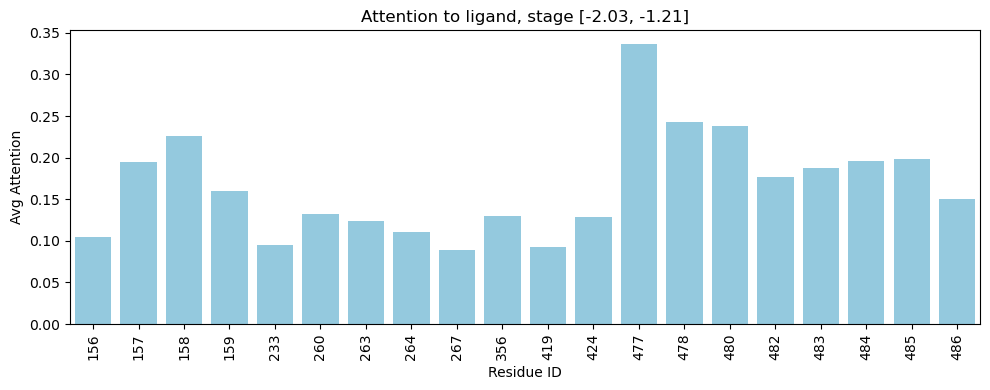

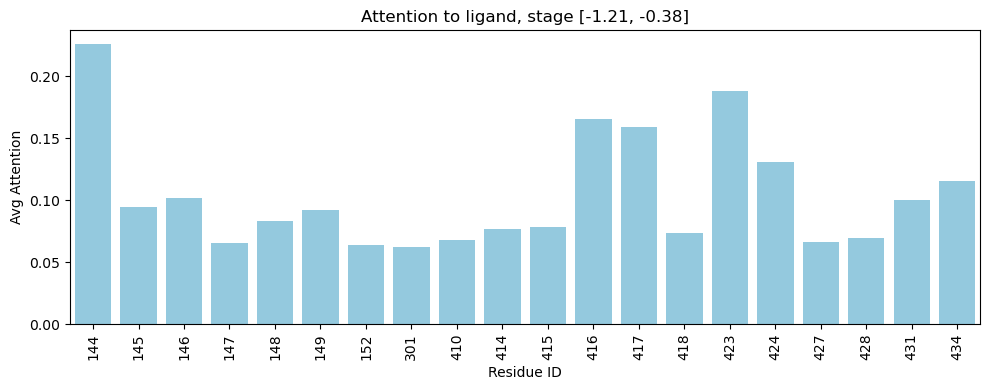

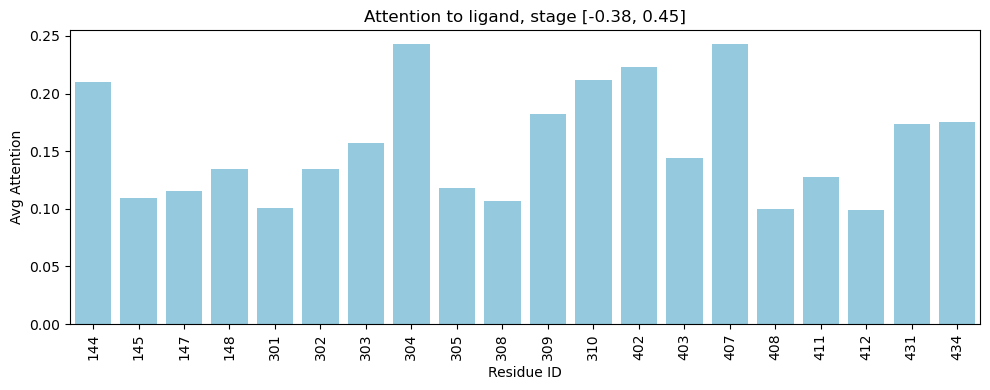

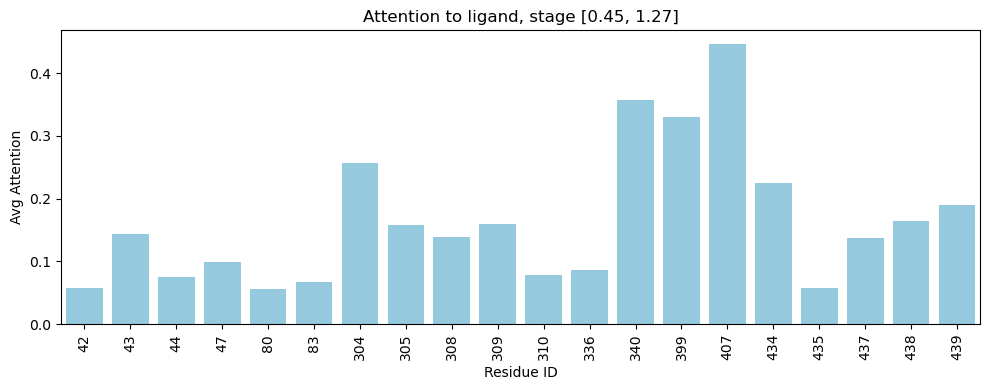

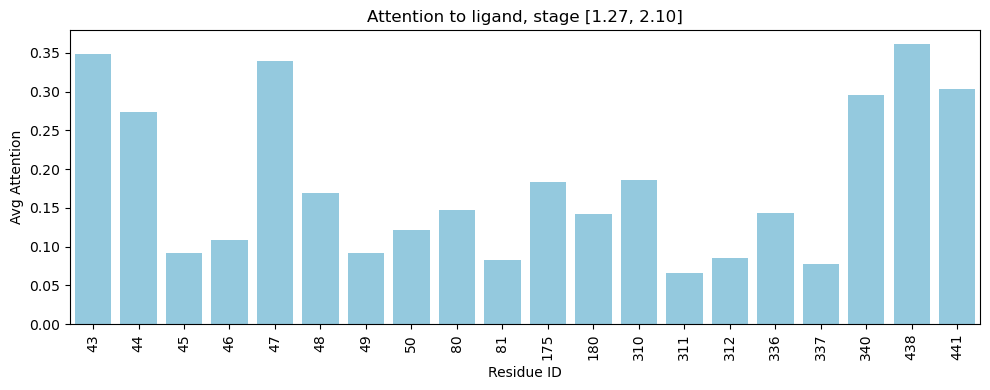

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns

def plot_attention_bins(attn_by_stage, top_n=20, out_dir=OUT_DIR):
    os.makedirs(out_dir, exist_ok=True)
    
    for (lo, hi), d in attn_by_stage.items():
        if not d:
            continue
        sorted_res = sorted(d.items(), key=lambda kv: kv[1], reverse=True)[:top_n]
        residues, scores = zip(*sorted_res)

        plt.figure(figsize=(10,4))
        sns.barplot(x=residues, y=scores, color="skyblue")
        plt.title(f"Attention to ligand, stage [{lo:.2f}, {hi:.2f}]")
        plt.xlabel("Residue ID")
        plt.ylabel("Avg Attention")
        plt.xticks(rotation=90)
        plt.tight_layout()
        
        out_path = os.path.join(out_dir, f"plot_stage_{lo:.2f}_{hi:.2f}.png")
        plt.savefig(out_path, dpi=150)
        plt.show()
        plt.close()

# Run plotting
plot_attention_bins(attn_by_stage, top_n=20)

In [48]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import defaultdict

def plot_attention_vs_zbin_heatmap(model, dataloader, num_bins=20, device="cuda"):
    model.eval()
    bin_attention = defaultdict(list)
    
    with torch.no_grad():
        for batch in dataloader:
            batch = batch.to(device)
            
            # Forward pass to get attention
            _, attn_weights = model(batch, return_attention=True)  # assumes your model can return attention
            
            # Each batch has one graph, so map z to bin
            z_val = batch.y.item()
            z_bin = int(np.floor((z_val + 2) / (4 / num_bins)))  # mapping z ∈ [-2,2] to bins
            
            # Mean attention per residue
            residue_attn = attn_weights.mean(dim=0).cpu().numpy()  
            for res_id, attn in zip(batch.residue_ids.cpu().numpy(), residue_attn):
                if res_id != -1:  # skip ligand
                    bin_attention[z_bin].append((res_id, attn))
    
    # Aggregate: mean per residue per bin
    bins = sorted(bin_attention.keys())
    residues = sorted({res for vals in bin_attention.values() for res, _ in vals})
    heatmap_matrix = np.zeros((len(residues), len(bins)))
    
    for j, b in enumerate(bins):
        res_to_attn = defaultdict(list)
        for res, attn in bin_attention[b]:
            res_to_attn[res].append(attn)
        for i, res in enumerate(residues):
            if res in res_to_attn:
                heatmap_matrix[i, j] = np.mean(res_to_attn[res])
    
    plt.figure(figsize=(12, 6))
    sns.heatmap(
        heatmap_matrix, 
        xticklabels=[f"Bin {b}" for b in bins], 
        yticklabels=residues, 
        cmap="viridis"
    )
    plt.xlabel("Ligand z-bin")
    plt.ylabel("Residue ID")
    plt.title("Attention heatmap: Residue vs Ligand z-bin")
    plt.show()


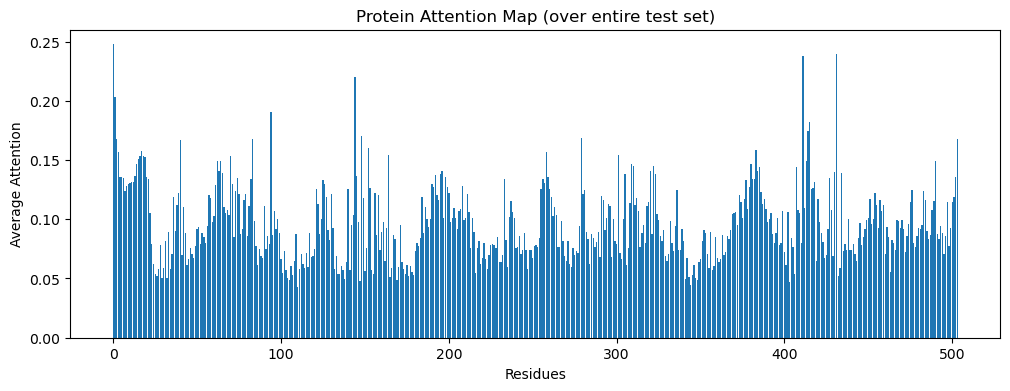

In [48]:
def compute_protein_attention_map(model, test_loader, device, use_layer=2):
    model.eval()
    residue_attention = None
    residue_counts = None

    with torch.no_grad():
        for data in test_loader:
            data = data.to(device)

            # Extract attention with your custom method
            att = model.get_attention_single(data)

            edge_index = att['edge_index'].cpu()
            alpha = att['alpha2' if use_layer == 2 else 'alpha1'].detach().cpu()

            src, dst = edge_index
            for s, d, w in zip(src.numpy(), dst.numpy(), alpha.numpy()):
                # skip ligand nodes
                if data.residue_ids[s] == -1 or data.residue_ids[d] == -1:
                    continue

                for node in [s, d]:
                    res_id = int(data.residue_ids[node].item())
                    if residue_attention is None:
                        n_res = int(data.residue_ids.max().item()) + 1
                        residue_attention = np.zeros(n_res)
                        residue_counts = np.zeros(n_res)

                    residue_attention[res_id] += w
                    residue_counts[res_id] += 1

    # Normalize
    protein_attention = residue_attention / (residue_counts + 1e-8)

    # Plot
    plt.figure(figsize=(12, 4))
    plt.bar(range(len(protein_attention)), protein_attention)
    plt.xlabel("Residues")
    plt.ylabel("Average Attention")
    plt.title("Protein Attention Map (over entire test set)")
    plt.show()

    return protein_attention

protein_attention = compute_protein_attention_map(model, test_loader, device, use_layer=2)

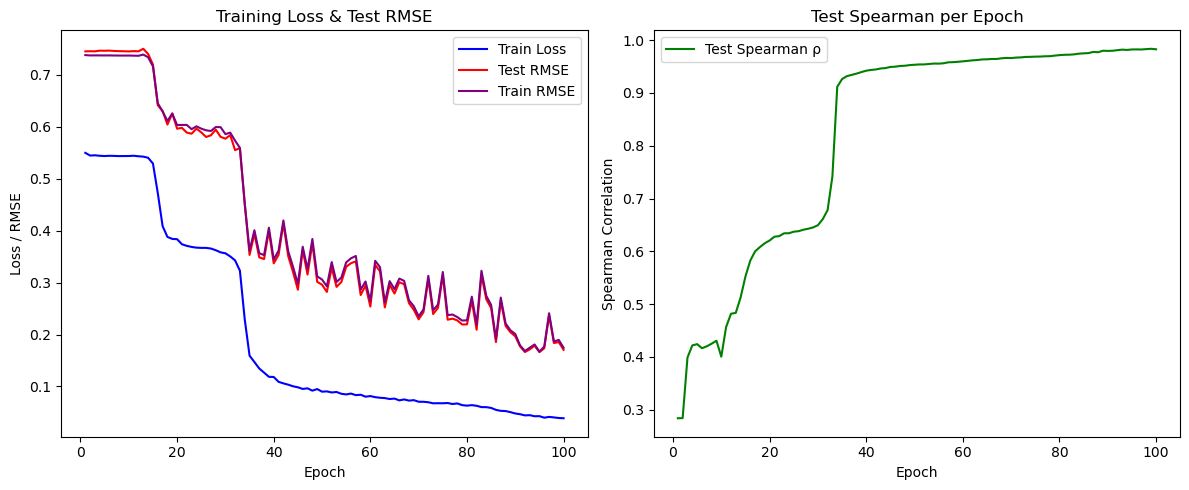

In [49]:
import matplotlib.pyplot as plt

epochs_range = range(1, epochs + 1)

plt.figure(figsize=(12, 5))

# Loss curve
plt.subplot(1, 2, 1)
plt.plot(epochs_range, train_losses, label="Train Loss", color="blue")
plt.plot(epochs_range, test_rmses, label="Test RMSE", color="red")
plt.plot(epochs_range, train_rmses, label="Train RMSE", color="purple")
plt.xlabel("Epoch")
plt.ylabel("Loss / RMSE")
plt.title("Training Loss & Test RMSE")
plt.legend()

# Spearman correlation
plt.subplot(1, 2, 2)
plt.plot(epochs_range, test_spearmans, label="Test Spearman ρ", color="green")
plt.xlabel("Epoch")
plt.ylabel("Spearman Correlation")
plt.title("Test Spearman per Epoch")
plt.legend()

plt.tight_layout()
plt.show()

/home/arnab/anaconda3/envs/torch/lib/python3.12/site-packages/sklearn/metrics/_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


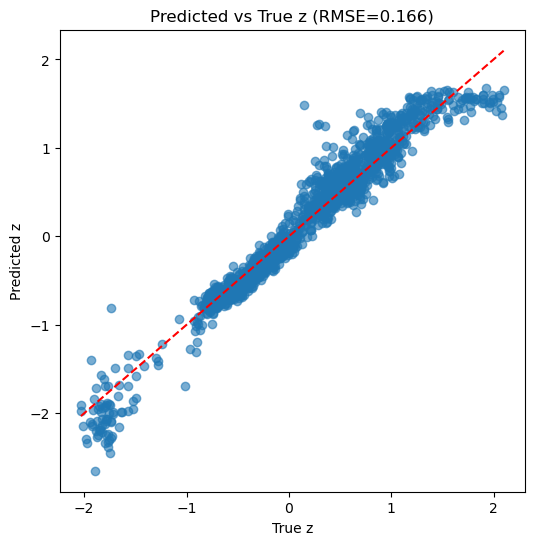

In [50]:
from sklearn.metrics import mean_squared_error
import numpy as np

model.load_state_dict(torch.load(best_path,weights_only=False)["model_state"])
model.eval()

y_true, y_pred = [], []
with torch.no_grad():
    for data in test_loader:
        data = data.to(device)
        pred = model(data).cpu().numpy()
        y_pred.extend(pred)
        y_true.extend(data.y.cpu().numpy())

y_true, y_pred = np.array(y_true), np.array(y_pred)
rmse = mean_squared_error(y_true, y_pred, squared=False)

plt.figure(figsize=(6, 6))
plt.scatter(y_true, y_pred, alpha=0.6)
plt.plot([y_true.min(), y_true.max()], [y_true.min(), y_true.max()], "r--")
plt.xlabel("True z")
plt.ylabel("Predicted z")
plt.title(f"Predicted vs True z (RMSE={rmse:.3f})")
plt.show()

In [30]:
def compute_protein_attention_by_bins(model, dataset, device, bin_width=1.0, use_layer=2):
    """
    Returns a dict: { (z_lo, z_hi): protein_attention_vector }
    where protein_attention_vector has length = max residue_id + 1
    """
    model.eval()

    # Build z-coordinate bins from dataset labels (y-values)
    ys = np.array([float(d.y.item()) for d in dataset])
    edges = bin_edges_from_range(ys, bin_width=bin_width)
    bins = list(zip(edges[:-1], edges[1:]))

    # Initialize accumulators per bin
    bin_residue_sum = {b: None for b in bins}
    bin_residue_count = {b: None for b in bins}

    with torch.no_grad():
        for data in dataset:
            y = float(data.y.item())
            b_idx = max(0, min(len(bins) - 1, np.searchsorted(edges, y) - 1))
            b = bins[b_idx]

            att = model.get_attention_single(data.to(device))
            edge_index = att['edge_index'].cpu()
            alpha = att['alpha2' if use_layer == 2 else 'alpha1'].detach().cpu()

            src, dst = edge_index
            for s, d, w in zip(src.numpy(), dst.numpy(), alpha.numpy()):
                if data.residue_ids[s] == -1 or data.residue_ids[d] == -1:
                    continue

                for node in [s, d]:
                    res_id = int(data.residue_ids[node].item())
                    n_res = int(data.residue_ids.max().item()) + 1

                    if bin_residue_sum[b] is None:
                        bin_residue_sum[b] = np.zeros(n_res)
                        bin_residue_count[b] = np.zeros(n_res)

                    bin_residue_sum[b][res_id] += w
                    bin_residue_count[b][res_id] += 1

    # Normalize
    bin_attention = {}
    for b in bins:
        if bin_residue_sum[b] is None:
            continue
        bin_attention[b] = bin_residue_sum[b] / (bin_residue_count[b] + 1e-8)

    return bin_attention


In [31]:
def plot_protein_attention_by_bins(bin_attention):
    """
    bin_attention: dict from compute_protein_attention_by_bins
    Plots a heatmap: bins (rows) × residues (columns)
    """
    bins = list(bin_attention.keys())
    bins_str = [f"[{lo:.1f}, {hi:.1f}]" for (lo, hi) in bins]
    att_matrix = np.array([bin_attention[b] for b in bins if bin_attention[b] is not None])

    plt.figure(figsize=(12, 6))
    sns.heatmap(att_matrix, cmap="Reds", cbar_kws={"label": "Avg Attention"})
    plt.yticks(np.arange(len(bins)) + 0.5, bins_str, rotation=0)
    plt.xlabel("Residues")
    plt.ylabel("Z-bins")
    plt.title("Protein Attention Map across Z-bins")
    plt.show()


In [32]:
# Compute residue-wise attention vectors per z-bin
#bin_attention = compute_protein_attention_by_bins(model, test_set, device, bin_width=1.0, use_layer=2)

# Visualize shifts in attention across bins
plot_protein_attention_by_bins(bin_attention)


NameError: name 'bin_attention' is not defined

In [51]:
import seaborn as sns

def plot_attention_by_stage(attention_by_stage: dict, threshold: float = 0.15):
    """
    Plots a heatmap of residue attentions across z-bins, only keeping residues
    whose attention variation > threshold.
    
    Parameters
    ----------
    attention_by_stage : dict
        Output of extract_attention_by_stage:
        { (z_lo, z_hi): {residue_id: avg_alpha_to_ligand} }
    threshold : float
        Min (max-min) attention difference across bins to keep residue.
    """

    # Extract bins and residue ids
    bins = list(attention_by_stage.keys())
    bins_str = [f"[{b[0]:.1f}, {b[1]:.1f}]" for b in bins]
    all_residues = sorted({rid for d in attention_by_stage.values() for rid in d.keys()})

    # Build matrix (bins × residues)
    mat = np.zeros((len(bins), len(all_residues)))
    for i, b in enumerate(bins):
        for j, rid in enumerate(all_residues):
            mat[i, j] = attention_by_stage[b].get(rid, 0.0)

    # Transpose -> residues × bins
    mat = mat.T

    # Filter residues by variation
    variation = mat.max(axis=1) - mat.min(axis=1)
    mask = variation > threshold
    mat_filtered = mat[mask]
    residues_filtered = np.array(all_residues)[mask]

    # Sort residues numerically
    sort_idx = np.argsort(residues_filtered)
    mat_filtered = mat_filtered[sort_idx]
    residues_filtered = residues_filtered[sort_idx]

    # Plot heatmap
    plt.figure(figsize=(12, max(6, 0.3*len(residues_filtered))))
    sns.heatmap(mat_filtered, xticklabels=bins_str, yticklabels=residues_filtered,
                cmap="Reds", cbar_kws={'label': 'Attention'})
    plt.xlabel("Z-bins")
    plt.ylabel("Residue ID")
    plt.title(f"Residue Attention by Transport Stage (Δ > {threshold})")
    plt.show()

    return residues_filtered, mat_filtered

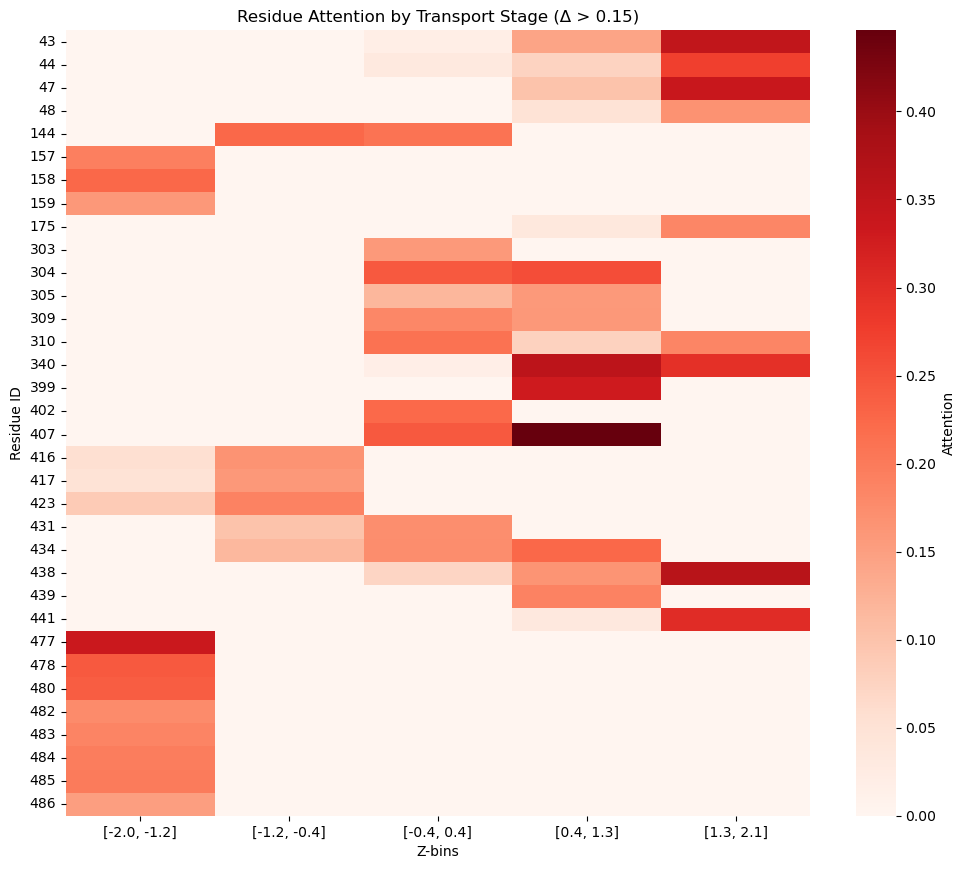

In [52]:
residues_filtered, mat_filtered = plot_attention_by_stage(attn_by_stage, threshold=0.15)

In [53]:
def plot_attention_by_stage(attention_by_stage: dict, threshold: float = 0.15):
    """
    Plots a heatmap of residue attentions across z-bins, keeping only residues
    with attention variation > threshold.

    Parameters
    ----------
    attention_by_stage : dict
        Output of extract_attention_by_stage:
        { (z_lo, z_hi): {residue_id: avg_alpha_to_ligand} }
    threshold : float
        Min (max-min) attention difference across bins to keep residue.
    """

    # Extract bins and residues
    bins = list(attention_by_stage.keys())
    all_residues = sorted({rid for d in attention_by_stage.values() for rid in d.keys()})

    # Build matrix: bins × residues
    mat = np.zeros((len(bins), len(all_residues)))
    for i, b in enumerate(bins):
        for j, rid in enumerate(all_residues):
            mat[i, j] = attention_by_stage[b].get(rid, 0.0)

    # Transpose -> residues × bins
    mat = mat.T

    # Filter residues by variation
    variation = mat.max(axis=1) - mat.min(axis=1)
    mask = variation > threshold
    mat_filtered = mat[mask]
    residues_filtered = np.array(all_residues)[mask]

    # Sort residues numerically
    sort_idx = np.argsort(residues_filtered)
    mat_filtered = mat_filtered[sort_idx]
    residues_filtered = residues_filtered[sort_idx]

    # Flip bins for descending order (positive → top, negative → bottom)
    bins_desc = bins[::-1]
    mat_filtered = mat_filtered[:, ::-1]  # reverse columns to match bins_desc

    # Convert bins to string labels
    bins_str = [f"[{b[0]:.1f}, {b[1]:.1f}]" for b in bins_desc]

    # Plot heatmap: residues (x-axis), bins (y-axis)
    plt.figure(figsize=(12, 3))
    sns.heatmap(mat_filtered.T, 
                xticklabels=residues_filtered, 
                yticklabels=bins_str, 
                cmap="BuPu", 
                cbar_kws={'label': 'Attention'},
                square=False)

    plt.xlabel("Residue ID")
    plt.ylabel("Z-bin")
    plt.title(f"Residue Attention by Transport Stage")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

    return residues_filtered, mat_filtered

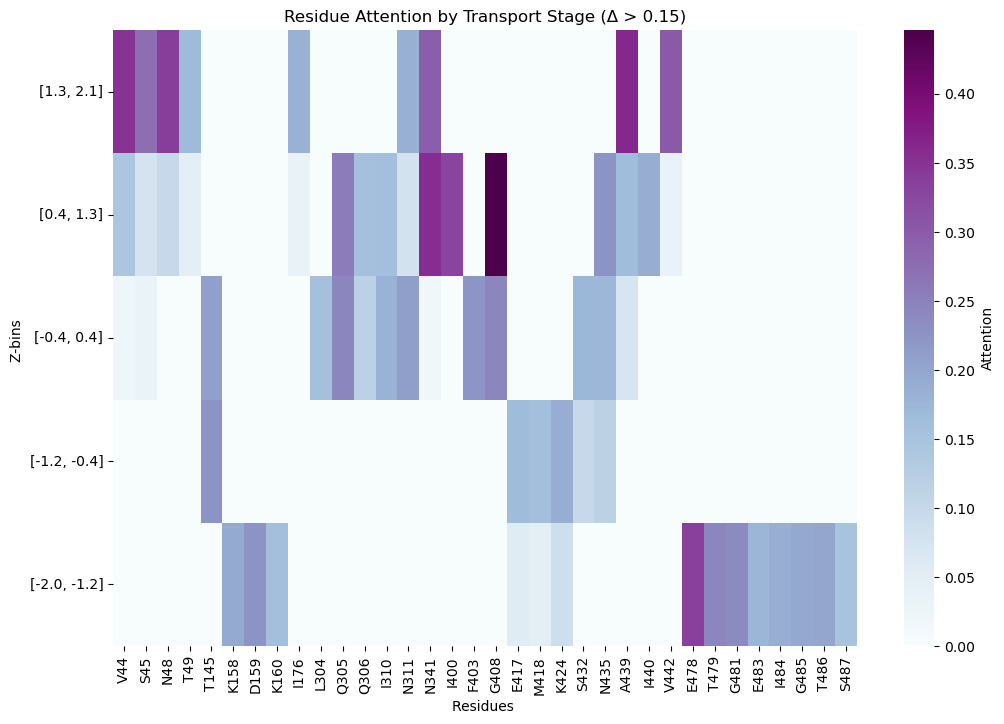

ValueError: too many values to unpack (expected 2)

In [59]:
residues_filtered, mat_filtered = plot_attention_by_stage(attn_by_stage, threshold=0.15)

In [60]:
residues_filtered

array([ 43,  44,  47,  48, 144, 157, 158, 159, 175, 303, 304, 305, 309,
       310, 340, 399, 402, 407, 416, 417, 423, 431, 434, 438, 439, 441,
       477, 478, 480, 482, 483, 484, 485, 486])

In [56]:
mat_filtered

array([[0.34897871, 0.14341591, 0.01917188, 0.        , 0.        ],
       [0.27364555, 0.07496253, 0.0317633 , 0.        , 0.        ],
       [0.3392977 , 0.09966698, 0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.21028035, 0.2258453 , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.22583665],
       [0.        , 0.25669512, 0.24269809, 0.        , 0.        ],
       [0.18608359, 0.07809842, 0.21160642, 0.        , 0.        ],
       [0.29572871, 0.35650545, 0.01850053, 0.        , 0.        ],
       [0.        , 0.32960997, 0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.22318714, 0.        , 0.        ],
       [0.        , 0.44606957, 0.24256166, 0.        , 0.        ],
       [0.        , 0.22549797, 0.17503803, 0.11583024, 0.        ],
       [0.36092779, 0.16404007, 0.07295844, 0.        , 0.        ],
       [0.30289182, 0.03319619, 0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.

In [57]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# FASTA sequence
fasta_seq = (
    "MTKSSKDICSENEGKKNGKSGFFSTSFKYVLSACIASFIFGYQVSVLNTIKNFIVVEFEWCKGEKDRLNCSNNTIQSSFLLASVFIGAVLGCGFSGYLVQFGRRLSLLIIYNFFFLVSILTSITHHFHTILFARLLSGFGIGLVTVSVPMYISEMTHKDKKGAYGVMHQLFITFGIFVAVMLGLAMGEGPKADSTEPLTSFAKLWWRLMFLFPSVISLIGILALVVFFKEETPYFLFEKGRIEESKNILKKIYETDNVDEPLNAIKEAVEQNESAKKNSLSLLSALKIPSYRYVIILGCLLSGLQQFTGINVLVSNSNELYKEFLDSHLITILSVVMTAVNFLMTFPAIYIVEKLGRKTLLLWGCVGVLVAYLPTAIANEINRNSNFVKILSIVATFVMIISFAVSYGPVLWIYLHEMFPSEIKDSAASLASLVNWVCAIIVVFPSDIIIKKSPSILFIVFSVMSILTFFFIFFFIKETKGGEIGTSPYITMEERQKHMTKSVV"
)

# Residue labels: one-letter + index (1-indexed for biology convention)
residue_labels = [f"{res}{i+1}" for i, res in enumerate(fasta_seq)]


def plot_attention_by_stage(attention_by_stage: dict, threshold: float = 0.15):
    """
    Plots a heatmap of residue attentions across z-bins, keeping only residues
    with attention variation > threshold. Residues labeled as 1-letter+Index.

    Parameters
    ----------
    attention_by_stage : dict
        Output of extract_attention_by_stage:
        { (z_lo, z_hi): {residue_id: avg_alpha_to_ligand} }
    threshold : float
        Min (max-min) attention difference across bins to keep residue.
    """

    # Extract bins and residues
    bins = list(attention_by_stage.keys())
    all_residues = sorted({rid for d in attention_by_stage.values() for rid in d.keys()})

    # Build matrix: bins × residues
    mat = np.zeros((len(bins), len(all_residues)))
    for i, b in enumerate(bins):
        for j, rid in enumerate(all_residues):
            mat[i, j] = attention_by_stage[b].get(rid, 0.0)

    # Filter residues by variation
    variation = mat.max(axis=0) - mat.min(axis=0)
    mask = variation > threshold
    mat_filtered = mat[:, mask]
    residues_filtered = np.array(all_residues)[mask]

    # Sort residues numerically
    sort_idx = np.argsort(residues_filtered)
    mat_filtered = mat_filtered[:, sort_idx]
    residues_filtered = residues_filtered[sort_idx]

    # Map residue IDs → 1-letter + Index
    resnames_filtered = [
        residue_labels[r] if r < len(residue_labels) else f"UNK{r}"
        for r in residues_filtered
    ]

    # Sort bins by descending z (hi → lo)
    bins_sorted = sorted(bins, key=lambda x: x[1], reverse=True)
    bins_str = [f"[{b[0]:.1f}, {b[1]:.1f}]" for b in bins_sorted]

    mat_sorted = np.zeros((len(bins_sorted), len(residues_filtered)))
    for i, b in enumerate(bins_sorted):
        for j, rid in enumerate(residues_filtered):
            mat_sorted[i, j] = attention_by_stage[b].get(rid, 0.0)

    # Plot heatmap
    plt.figure(figsize=(max(12, 0.3*len(residues_filtered)), 8))
    sns.heatmap(mat_sorted, xticklabels=resnames_filtered, yticklabels=bins_str,
                cmap="BuPu", cbar_kws={'label': 'Attention'})
    plt.xlabel("Residues ")
    plt.ylabel("Z-bins ")
    plt.title(f"Residue Attention by Transport Stage (Δ > {threshold})")
    plt.xticks(rotation=90)
    plt.yticks(rotation=0)
    plt.show()

    return residues_filtered, resnames_filtered, mat_sorted


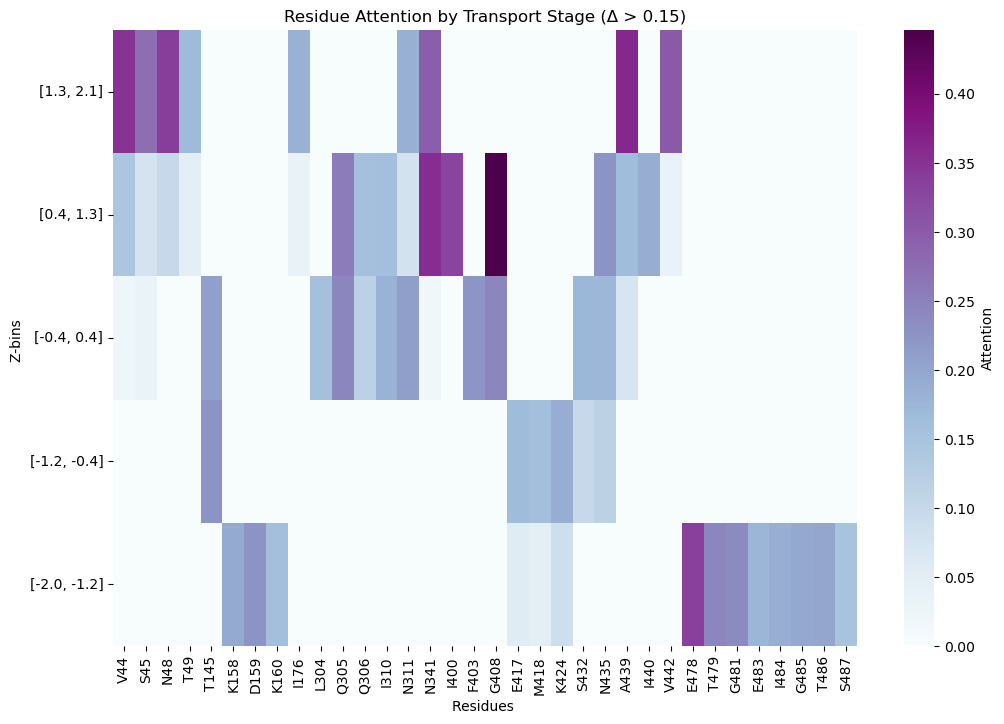

In [58]:
residues_filtered, resnames_filtered, mat_filtered = plot_attention_by_stage(attn_by_stage, threshold=0.15)

In [112]:
fasta_seq = (
    "MTKSSKDICSENEGKKNGKSGFFSTSFKYVLSACIASFIFGYQVSVLNTIKNFIVVEFEWCKGEKDRLNCSNNTIQSSFLLASVFIGAVLGCGFSGYLVQFGRRLSLLIIYNFFFLVSILTSITHHFHTILFARLLSGFGIGLVTVSVPMYISEMTHKDKKGAYGVMHQLFITFGIFVAVMLGLAMGEGPKADSTEPLTSFAKLWWRLMFLFPSVISLIGILALVVFFKEETPYFLFEKGRIEESKNILKKIYETDNVDEPLNAIKEAVEQNESAKKNSLSLLSALKIPSYRYVIILGCLLSGLQQFTGINVLVSNSNELYKEFLDSHLITILSVVMTAVNFLMTFPAIYIVEKLGRKTLLLWGCVGVLVAYLPTAIANEINRNSNFVKILSIVATFVMIISFAVSYGPVLWIYLHEMFPSEIKDSAASLASLVNWVCAIIVVFPSDIIIKKSPSILFIVFSVMSILTFFFIFFFIKETKGGEIGTSPYITMEERQKHMTKSVV"
)

# Residue indices (0-based)
res_indices = [
    76, 77, 79, 80, 81, 83, 144, 158, 260, 309, 310, 311, 313,
    314, 315, 316, 317, 318, 331, 356, 399, 407, 408, 427, 430, 431,
    434, 435, 438, 439, 442, 445, 446, 477, 478, 480
]

# Build mapping
residues_with_names = []
for rid in res_indices:
    if rid < len(fasta_seq):
        resname = fasta_seq[rid]  # one-letter code
        residues_with_names.append(f"{resname}{rid+1}")  # convert to 1-based
    else:
        residues_with_names.append(f"{rid+1}UNK")  # safeguard

print(residues_with_names)


['S77', 'S78', 'L80', 'L81', 'A82', 'V84', 'T145', 'D159', 'P261', 'I310', 'N311', 'V312', 'V314', 'S315', 'N316', 'S317', 'N318', 'E319', 'I332', 'R357', 'I400', 'G408', 'P409', 'A428', 'A431', 'S432', 'N435', 'W436', 'A439', 'I440', 'V443', 'S446', 'D447', 'E478', 'T479', 'G481']
